In [2]:
%load_ext autoreload
%autoreload 1
%aimport PileUp_analysis.utility.functions
%aimport PileUp_analysis.src.analysis
%aimport PileUp_analysis.src.dataset
%aimport PileUp_analysis.src.high_analysis
import numpy as np
import PileUp_analysis.utility.functions as fn
import PileUp_analysis.src.analysis as an
import PileUp_analysis.src.dataset as ds
import PileUp_analysis.src.high_analysis as ha
import matplotlib.pyplot as plt
import optuna
from plotly.io import show
import plotly.graph_objects as go

In [3]:
fn.calculate_BI(0.90,0.8)

2.6377169023542848e-05

In [ ]:
for channel in [3,5,9,11,13,15,17,19]:
    mean, bslspec = ds.get_meanpulse_ANPS(channel)
    data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = ds.create_data_sets(channel,-1,pos_prefix="_bis")
    transf_OF,_ = an.compute_transfer_simple(mean, bslspec)
    
    best_params,_= ds.get_best_param(channel)
    mg = fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_PU,_ = an.compute_transfer_simple(mean,mg*bslspec )
    
    filtered_amp_single, argmax_single = an.get_interpolate_filtered_amp(data_single, transf_PU, arg_max=1999)
    fitted_amp_single = an.get_interpolate_fitted_amp(data_single, transf_PU, argmax_single, mean,jitter = 150)
    chi2_single = an.get_interpolate_chi2(data_single, transf_PU, argmax_single, mean)
    
    filtered_amp_pileup, argmax_pileup = an.get_interpolate_filtered_amp(data_pileup, transf_PU, arg_max=1999)
    fitted_amp_pileup = an.get_interpolate_fitted_amp(data_pileup, transf_PU, argmax_pileup, mean,jitter = 150)
    chi2_pileup = an.get_interpolate_chi2(data_pileup, transf_PU, argmax_pileup, mean)
    PSD_single = filtered_amp_single[:,0]/fitted_amp_single
    PSD_pileup = filtered_amp_pileup[:,0]/fitted_amp_pileup
    cut = np.percentile(PSD_single,10)
    rp = np.sum(PSD_pileup<cut)/len(PSD_pileup)
    print(channel,rp,fn.calculate_BI(rp,0.8)*1e5)

In [23]:
for channel in [3,5,9,11,13,15,17,19]:
    meanpulse, bslspec = ds.get_meanpulse_ANPS(channel)
    data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = ds.create_data_sets(channel,-2,pos_prefix="_bis")
    transf_OF,_ = an.compute_transfer_simple(meanpulse, bslspec)
    
    best_params,_= ds.get_best_param(channel)
    mg = fn.modified_gaussian(np.fft.fftfreq(4000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_PU = transf_OF/mg
    PSD_single, filtered_amp_single, _, _ = an.get_PSD(data_single, transf_PU, meanpulse, transferfunc_max = transf_OF)
    PSD_pileup, filtered_amp_pileup, _, _ = an.get_PSD(data_pileup, transf_PU, meanpulse, transferfunc_max = transf_OF)
    cut = np.percentile(PSD_single, 10)
    rp = np.sum(PSD_pileup < cut) / len(PSD_pileup)
    BI = fn.calculate_BI(rp, 0.8)
    print(rp,BI)

0.7999333333333334 5.277192282643472e-05
0.7808666666666667 5.7801169720256896e-05
0.7608666666666667 6.307660352496547e-05
0.7774 5.871557824640639e-05
0.8019333333333334 5.224437944596386e-05
0.7138666666666666 7.547387296603063e-05
0.7744666666666666 5.948930853776366e-05
0.7109333333333333 7.624760325738788e-05


In [24]:
for channel in [3,5,9,11,13,15,17,19]:
    meanpulse, bslspec = ds.get_meanpulse_ANPS(channel)
    data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = ds.create_data_sets(channel,-2,pos_prefix="_bis")
    partial = 0 if channel != 17 else 1
    bslspec_marria = np.fromfile(f"/media/mp274748/Transcend/data/LSC/RUN9_pulse_injected/nps/pup_n1-d0_000813_20230628T161508_{channel:03}_{partial:03}_diff.bin_spec.bin.dif")
    transf_mariia,_ = an.compute_transfer_simple(meanpulse, bslspec_marria)
    
    best_params,_= ds.get_best_param(channel)
    mg = fn.modified_gaussian(np.fft.fftfreq(4000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_PU = transf_OF/mg
    PSD_single, filtered_amp_single, _, _ = an.get_PSD(data_single, transf_mariia, meanpulse, transferfunc_max = transf_mariia)
    PSD_pileup, filtered_amp_pileup, _, _ = an.get_PSD(data_pileup, transf_mariia, meanpulse, transferfunc_max = transf_mariia)
    cut = np.percentile(PSD_single, 10)
    rp = np.sum(PSD_pileup < cut) / len(PSD_pileup)
    BI = fn.calculate_BI(rp, 0.8)
    print(rp,BI)

0.7475333333333334 6.659355939477119e-05
0.7259333333333333 7.229102790385646e-05
0.7348 6.995225225043565e-05
0.7602 6.325245131845576e-05
0.7714666666666666 6.028062360846995e-05
0.6770666666666667 8.518067116669437e-05
0.7358666666666667 6.967089578085119e-05
0.6676666666666666 8.766012505490743e-05


In [25]:
for channel in [3,5,9,11,13,15,17,19]:
    meanpulse, bslspec = ds.get_meanpulse_ANPS(channel)
    data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = ds.create_data_sets(channel,-2,pos_prefix="_bis")
    partial = 0 if channel != 17 else 1
    # bslspec_marria = np.fromfile(f"/media/mp274748/Transcend/data/LSC/RUN9_pulse_injected/nps/pup_n1-d0_000813_20230628T161508_{channel:03}_{partial:03}_diff.bin_spec.bin.dif")
    transf_OF,_ = an.compute_transfer_simple(meanpulse, bslspec)
    
    best_params,_= ds.get_best_param(channel)
    mg = fn.modified_gaussian(np.fft.fftfreq(4000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_PU = transf_OF/mg
    PSD_single, filtered_amp_single, _, _ = an.get_PSD(data_single, transf_OF, meanpulse, transferfunc_max = transf_OF)
    PSD_pileup, filtered_amp_pileup, _, _ = an.get_PSD(data_pileup, transf_OF, meanpulse, transferfunc_max = transf_OF)
    cut = np.percentile(PSD_single, 10)
    rp = np.sum(PSD_pileup < cut) / len(PSD_pileup)
    BI = fn.calculate_BI(rp, 0.8)
    print(rp,BI)

0.7456 6.7103517995893e-05
0.7062 7.74961225911689e-05
0.6907333333333333 8.157579140014354e-05
0.7131333333333333 7.566730553886995e-05
0.7415333333333334 6.817618953618375e-05
0.6161333333333333 0.0001012531594917065
0.7088 7.681031619655679e-05
0.6190666666666667 0.00010047942920034928


In [16]:
from torch.utils.data import DataLoader
from scipy.interpolate import interp1d
dataset = data_pileup
transferfunc = transf_PU
transferfunc_max = transf_OF
arg_max=1999
subsample_size=0.01
jitter_max=4
jitter_fit=150
batch_size = 256
loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
transferfunc_max = transferfunc if transferfunc_max is None else transferfunc_max
mean_dif = np.diff(np.append(meanpulse, meanpulse[-1]))
fmeanpulse = an.get_filtered_pulse(mean_dif, transferfunc)
freq = np.fft.fftfreq(4000, 1e-4)
peak_values = []
peak_positions = []
coeffs = []
dts = []
for pulses in loader:
    if hasattr(pulses, 'numpy'):
        pulses = pulses.numpy()
    n_p, win_size = np.shape(pulses)
    row_indices = np.arange(n_p)[:, None]
    # Compute first derivative (difference)
    dpulses = np.diff(np.append(pulses, pulses[:, -1][:, None], axis = 1), axis = 1)
    f_pulse = np.fft.fft(dpulses, axis = 1)
    fpulses = np.real(np.fft.ifft(f_pulse * transferfunc_max))

    # Window of points around the peak to interpolate
    x = np.arange(-5, 6) + arg_max
    y = fpulses[:, arg_max - 5: arg_max + 6]

    # Interpolation function for sub-sample peak finding
    interp_func = interp1d(x, y, kind='cubic', axis=1, bounds_error=False, fill_value='extrapolate')
    x_inter = np.arange(-jitter_max, jitter_max+subsample_size, subsample_size) + arg_max
    inter_fpulse = interp_func(x_inter)
    arg_max_inter_sub = np.argmax(inter_fpulse, axis = 1)

    dt = (x_inter[arg_max_inter_sub] - arg_max) * 1e-4
    dts.append(dt)


(0.0, 2.0)

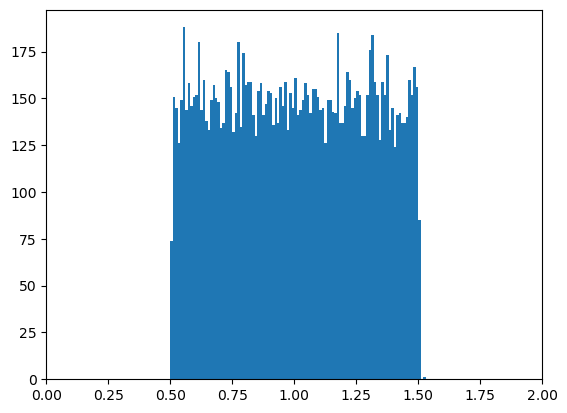

In [17]:
_=plt.hist(np.concatenate(dts) * 1e4,(x_inter - arg_max))
plt.xlim(0,2)

In [2]:
def prepare_global_dt_model(prompt, J=None, dt_global_range=(0.1e-6, 8e-6), dt_global_step=0.1e-6, fs=1e6):
    N = len(prompt)
    freq = np.fft.fftfreq(N, 1/fs)[:N//2 + 1]
    sp_tilde = np.fft.rfft(prompt)
    J = np.ones(N//2 + 1) if J is None else J

    dt_globals = np.arange(dt_global_range[0], dt_global_range[1], dt_global_step)

    phase_shifts = np.exp(1j * 2 * np.pi * freq[None, :] * dt_globals[:, None])  # shape: (n_dt, n_freq)
    
    return freq, sp_tilde, J, dt_globals, phase_shifts

def prepare_delay_model(prompt, J=None, delay_range=(0.1e-4, 8e-4), step=0.01e-4, fs=1e4):
    N = len(prompt)
    freq = np.fft.fftfreq(N, 1/fs)[:N//2 + 1]
    sp_tilde = np.fft.rfft(prompt)
    J = np.ones(N//2 + 1) if J is None else J

    dts = np.arange(delay_range[0], delay_range[1], step)
    dts = dts[np.abs(dts) > step * 0.5]
    
    # Precompute delayed pulse shapes
    phase_shifts = np.exp(-1j * 2 * np.pi * freq[None, :] * dts[:, None])
    so_tilde_all = sp_tilde[None, :] * phase_shifts  # (n_dt, n_freq)

    # Compute all M matrices
    spp = np.sum((np.abs(sp_tilde)**2) / J)
    soo = np.sum((np.abs(so_tilde_all)**2) / J, axis=1)
    spo = np.sum(np.real(sp_tilde.conj() * so_tilde_all) / J, axis=1)

    M_all = np.array([
        [[spp, spo_i],
         [spo_i, soo_i]]
        for spo_i, soo_i in zip(spo, soo)
    ])  # shape: (n_dt, 2, 2)

    return freq, sp_tilde, so_tilde_all, M_all, J, dts
def estimate_global_dt_from_model(p_tilde, sp_tilde, J, freq, dts, phase_shifts):
    n_pulses = pulses.shape[0]
    N = pulses.shape[1]
      # (n_pulses, n_freq)
    # Apply each phase shift to p_tilde: shape (n_pulses, n_dt, n_freq)
    shifted_tilde = p_tilde[:, None, :] * phase_shifts[None, :, :]  # broadcast over pulses and dts

    # Estimate Ap for each shift using matched filter:
    sp_tilde_ = sp_tilde[None, None, :]  # (1, 1, n_freq)
    J_ = J[None, None, :]  # (1, 1, n_freq)

    Ap_est = np.sum(np.real(sp_tilde_.conj() * shifted_tilde) / J_, axis=-1)/ np.sum((np.abs(sp_tilde)**2) / J) # (n_pulses, n_dt)

    # Reconstruct signal and compute error
    model = Ap_est[:, :, None] * sp_tilde[None, None, :]  # (n_pulses, n_dt, n_freq)
    error = np.sum(np.abs(shifted_tilde - model) ** 2, axis=-1)  # (n_pulses, n_dt)

    best_dt_idx = np.argmin(error, axis=1)
    best_dts = dts[best_dt_idx]
    best_ap = Ap_est[np.arange(n_pulses), best_dt_idx]
    best_phase_shift = phase_shifts[np.arange(n_pulses), best_dt_idx]
    best_ptilde = shifted_tilde[np.arange(n_pulses), best_dt_idx]
    return error, best_dts, best_ap, best_phase_shift,best_ptilde, Ap_est


def estimate_delay_and_amplitudes_from_model(p_tilde, sp_tilde, so_tilde_all, M_all, freq, J, dts):
    n_pulses = pulses.shape[0]
    n_dt = len(dts)
    N = pulses.shape[1]

    p_tilde = p_tilde

    # Compute b_p and b_o
    sp_tilde_ = sp_tilde[None, :]  # (1, n_freq)
    so_tilde_all_ = so_tilde_all[None, :, :]  # (1, n_dt, n_freq)
    J_ = J[None, None, :]  # (1, 1, n_freq)
    p_tilde_ = p_tilde[:, None, :]  # (n_pulses, 1, n_freq)

    b_p = np.sum(np.real(sp_tilde_.conj() * p_tilde_) / J_, axis=-1)  # (n_pulses, 1)
    b_o = np.sum(np.real(so_tilde_all_.conj() * p_tilde_) / J_, axis=-1)  # (n_pulses, n_dt)
    b_p = np.broadcast_to(b_p, b_o.shape)  # (n_pulses, n_dt)
    b_all = np.stack([b_p, b_o], axis=-1)  # (n_pulses, n_dt, 2)
    
    # Solve M @ x = b
    M_all_exp = np.broadcast_to(M_all[None, :, :, :], (n_pulses, n_dt, 2, 2))
    amplitudes = np.linalg.solve(M_all_exp, b_all)  # (n_pulses, n_dt, 2)
    Ap_est = amplitudes[..., 0]
    Ao_est = amplitudes[..., 1]

    # Reconstruct model and compute error
    model_tilde = (
        Ap_est[:, :, None] * sp_tilde[None, None, :] +
        Ao_est[:, :, None] * so_tilde_all[None, :, :]
    )
    error = np.sum(np.abs(p_tilde[:, None, :] - model_tilde) ** 2, axis=-1)

    best_dt_idx = np.argmin(error, axis=1)
    best_dts = dts[best_dt_idx]
    best_ap = Ap_est[np.arange(n_pulses), best_dt_idx]
    best_ao = Ao_est[np.arange(n_pulses), best_dt_idx]

    return error, best_dts, best_ap, best_ao

def compute_M(dt,sp_tilde,p_tilde,J):
    s_freq = (np.abs(sp_tilde)**2) / J
    spp = np.sum(s_freq)
    spo = np.sum(s_freq*np.cos(2 * np.pi * freq * dt))
    return spp,spo
def compute_bp_bo(sp_tilde,p_tilde):
    b_freq = np.real(sp_tilde.conj() * p_tilde) / J
    b_p = np.sum(b_freq)
    b_o = np.sum(b_freq * np.cos(2 * np.pi * freq * dt))
    return b_p,b_o
def compute_gamma(cos_dt, sp_tilde, J,):
    s_freq = (np.abs(sp_tilde)**2) / J  # (n_freq,)
    spp = np.sum(s_freq)  # scalar
    spo = np.sum(s_freq[:, None] * cos_dt, axis=0)  # (N_dt,)
    gamma = spo / spp  # (N_dt,)
    return gamma 
    
def compute_beta(p_tilde,sp_tilde,phase_shift,cos_dt):
    b_freq = np.real((p_tilde[:, None, :] * sp_tilde.conj()[None, None, :] * phase_shift[None, :, :]) / J)
    b_p = np.sum(b_freq, axis=2)  # (n_batch, N_t0)
    b_o = np.sum(b_freq[:, :, :, None] * cos_dt[None, None, :, :], axis=2)  # (n_batch, N_t0, N_dt)
    beta = b_p[:, :, None] / b_o  # (n_batch, N_t0, N_dt)
    return beta
def compute_error(t0, dt, p_tilde, sp_tilde,  J, freq ):
    p_tilde = p_tilde * np.exp(-1j * 2 * np.pi * freq* t0)
    try:
        so_tilde = sp_tilde* np.exp(-1j * 2 * np.pi * freq * dt)
        spp = np.sum((np.abs(sp_tilde)**2) / J)
        soo = np.sum((np.abs(so_tilde)**2) / J)
        spo = np.sum(np.real(sp_tilde.conj() * so_tilde) / J)
    
        M = np.array([[spp, spo], [spo, soo]])
        b_p = np.sum(np.real(sp_tilde.conj() * p_tilde) / J)
        b_o = np.sum(np.real(so_tilde.conj() * p_tilde) / J)
        b_all = np.stack([b_p, b_o]) 
        amplitudes = np.linalg.solve(M, b_all) 
        Ap_est = amplitudes[0]
        Ao_est = amplitudes[1]
        model_tilde = Ap_est * sp_tilde + Ao_est* so_tilde
        error = np.sum(np.abs(p_tilde - model_tilde) ** 2/J, axis=-1)
    except np.linalg.LinAlgError:
        Ap_est = np.sum(np.real(sp_tilde.conj() * p_tilde) / J)/ np.sum((np.abs(sp_tilde)**2) / J) 
        Ao_est = 0
        model_tilde = Ap_est * sp_tilde
        error = np.sum(np.abs(p_tilde - model_tilde) ** 2/J, axis=-1)
    if Ap_est<0 or Ao_est<0:
        print(np.linalg.det(M))
    return error , Ap_est,Ao_est

In [3]:

from torch.utils.data import DataLoader
channel = 3
mean, bslspec_dif = ds.get_meanpulse_ANPS(channel)
bslspec = np.fromfile(ds.main_dir + f"/channel{channel}/dif/raw_noise_diff.bin_spec.bin")
J = bslspec[:1001]
fs = 1e4
N = len(mean)
freq = np.fft.fftfreq(N, 1/fs)[:N//2 + 1]
data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = ds.create_data_sets(channel,-2,pos_prefix="_bis")
sp_tilde = np.fft.rfft(mean)
i = 0
loader = DataLoader(data_single, batch_size=64, shuffle=False)
curves_single = []
dts= np.arange(-8e-4,8e-4,1e-5)
t0s = np.arange(-0.5e-4,.5e-4,.1e-4)
phase_shift = np.exp(-1j * 2 * np.pi * freq[None, :] * t0s[:, None])  # (N_t0, n_freq)
cos_dt = np.cos(2 * np.pi * freq[:, None] * dt_array[None, :])  # (n_freq, N_dt)
for pulses in loader:
    p_tildes = np.fft.rfft(pulses[:,1000:3000],axis =1)
    
    betas,gamas = compute_beta_gamma(dts, t0s, sp_tilde, p_tildes, J, freq)
    argmin = np.argmin(np.sum(1/gamas[None,None,:]-betas,axis=2),axis=1)
    curves = 1/gamas[None,:]-betas[np.arange(betas.shape[0]),argmin,:]
    curves_single.append(curves)
curves_single = np.concatenate(curves_single)
loader = DataLoader(data_pileup, batch_size=64, shuffle=False)
curves_pileup = []
for pulses in loader:
    p_tildes = np.fft.rfft(pulses[:,1000:3000],axis =1)
    dts= np.arange(-8e-4,8e-4,1e-5)
    t0s = np.arange(-0.5e-4,.5e-4,.1e-4)
    betas,gamas = compute_beta_gamma(dts, t0s, sp_tilde, p_tildes, J, freq)
    argmin = np.argmin(np.sum(1/gamas[None,None,:]-betas,axis=2),axis=1)
    curves = 1/gamas[None,:]-betas[np.arange(betas.shape[0]),argmin,:]
    curves_pileup.append(curves)
curves_pileup = np.concatenate(curves_pileup)

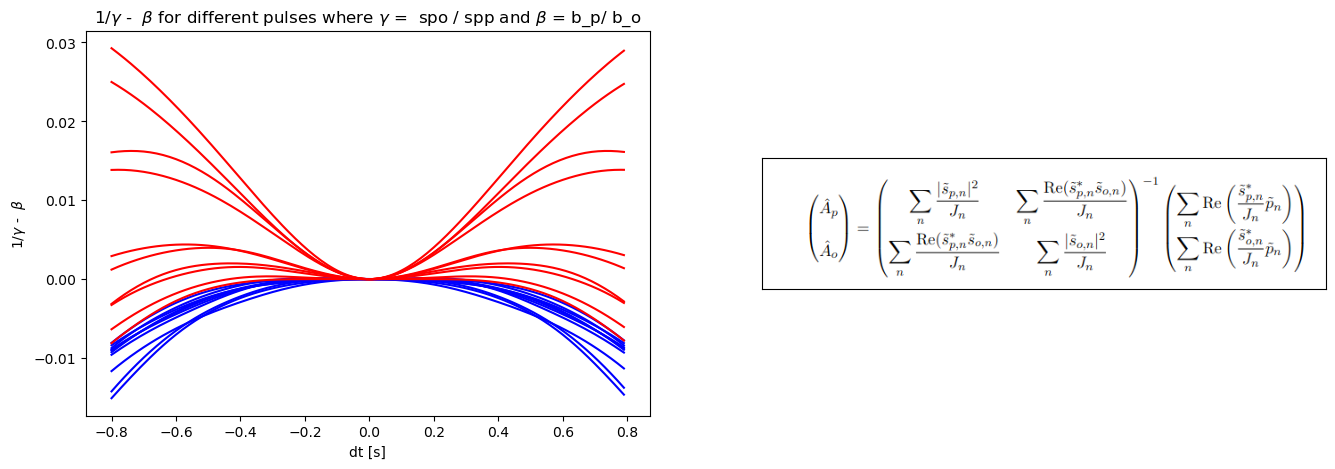

In [22]:
from PIL import Image
plt.figure(figsize=(16,5))
plt.subplot(121)
for cs in curves_single[:10]:
    plt.plot(dts*1e3,cs,c="b")
for cp in curves_pileup[:10]:
    plt.plot(dts*1e3,cp,c="r")
plt.xlabel("dt [s]")
plt.ylabel("1/$\gamma$ -  $\\beta$")
plt.title("1/$\gamma$ -  $\\beta$ for different pulses where $\gamma$ =  spo / spp and $\\beta$ = b_p/ b_o")
plt.subplot(122)
Matrix_eq = np.asarray(Image.open('/local/home/mp274748/Documents/presentation/pileup/matrix_eq.png'
                                  ''))
fig = plt.imshow(Matrix_eq)
fig.axes.get_xaxis().set_visible(False)
fig.axes.get_yaxis().set_visible(False)

[ 0.5366248  -0.90891561]
0.7854 5.660540472452296
0.7978666666666666 5.331705098625464


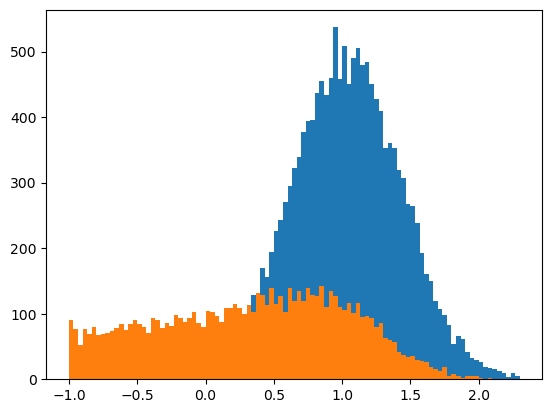

In [210]:
sum_s = np.sum(curves_single,axis=1)
sum_p = np.sum(curves_pileup,axis=1)
cut_s = np.percentile(sum_s,90)
p = np.polyfit(PSD_single,sum_s,1)
f = np.poly1d(p)
print(p)
para_s= sum_s/f(PSD_single)
para_p= sum_p/f(PSD_pileup)
plt.hist(para_s,np.linspace(-1,2.3,100))
plt.hist(para_p,np.linspace(-1,2.3,100))

cut_para = np.percentile(para_s,10)
print(np.sum(para_p<cut_para)/len(PSD_pileup),fn.calculate_BI(np.sum(para_p<cut_para)/len(PSD_pileup),0.8)*1e5)
# plt.hlines(cut_s,-10,10)
# # plt.scatter(PSD_single,np.sum(curves_single,axis=1)/PSD_single,s=0.6)
# hist1, xedges, yedges = np.histogram2d(PSD_single,sum_s,(np.arange(0.90,1.1,0.001),np.arange(-.7,0.5,0.01)))
# 
# plt.vlines(np.percentile(PSD_single,10),-10,10)
# hist2, _, _ = np.histogram2d(PSD_pileup,sum_p,(np.arange(0.90,1.1,0.001),np.arange(-.7,0.5,0.01)))
# # plt.scatter(PSD_pileup,np.sum(curves_pileup,axis=1)/PSD_pileup,s=0.6,alpha=1)
# plt.xlim(0.98,1.05)
# plt.ylim(-.7,0.5)
# hist_subtracted = hist1 - hist2
# hist_subtracted[hist_subtracted<0] = 0
# # Plot the result
# plt.pcolormesh(xedges, yedges, hist_subtracted.T, shading='auto')
# plt.colorbar(label='Subtracted counts')
# plt.xlabel('X')
# plt.ylabel('Y')
# plt.title('Histogram 1 - Histogram 2')
# plt.show()

# print(np.sum(sum_p>cut_s)/len(sum_p),fn.calculate_BI(np.sum(sum_p>cut_s)/len(sum_p),0.8)*1e5)
cut_PSD = np.percentile(PSD_single,10)
print(np.sum(PSD_pileup<cut_PSD)/len(PSD_pileup),fn.calculate_BI(np.sum(PSD_pileup<cut_PSD)/len(PSD_pileup),0.8)*1e5)
# percent = 6.5
# cut_PSD_bis= np.percentile(PSD_single,percent)
# cut_s_bis = np.percentile(sum_s,100-percent)
# cutted_pileup = (PSD_pileup<cut_PSD_bis)|(sum_p>cut_s_bis)
# cutted_single = (PSD_single<cut_PSD_bis)|(sum_s>cut_s_bis)
# print(np.sum(cutted_pileup)/len(PSD_pileup),np.sum(cutted_single)/len(sum_s))

In [617]:
for channel in [3]:
    meanpulse, bslspec = ds.get_meanpulse_ANPS(channel)
    data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = ds.create_data_sets(channel,-1,pos_prefix="_bis")
    best_params,_= ds.get_best_param(channel)
    mg = fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_OF,_ = an.compute_transfer_simple(meanpulse,bslspec)
    transf_PU,_ = an.compute_transfer_simple(meanpulse,bslspec/fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),10,np.log(1000),0.4,1))
    print(transf_PU.shape)
    PSD_single,filtered_amp_single,_,_ = an.get_PSD(data_single, transf_PU, meanpulse,transferfunc_max=transf_OF)
    PSD_pileup,filtered_amp_pileup,_,_ = an.get_PSD(data_pileup, transf_PU, meanpulse,transferfunc_max=transf_OF)
    cut = np.percentile(PSD_single,10)
    rp = np.sum(PSD_pileup<cut)/len(PSD_pileup)
    print(channel,np.sum(PSD_single>cut)/len(PSD_single),rp,fn.calculate_BI(rp,0.8)*1e5)
    # PSD_single,filtered_amp_single,_,_ = an.get_PSD(data_single, transf_OF, meanpulse,transferfunc_max=transf_OF)
    # PSD_pileup,filtered_amp_pileup,_,_ = an.get_PSD(data_pileup, transf_OF, meanpulse,transferfunc_max=transf_OF)
    # cut = np.percentile(PSD_single,10)
    # rp = np.sum(PSD_pileup<cut)/len(PSD_pileup)
    # print(channel,np.sum(PSD_single>cut)/len(PSD_single),rp,fn.calculate_BI(rp,0.8)*1e5)

(4000,)
3 0.9 0.7847333333333333 5.678125251801326


In [26]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from scipy.interpolate import interp1d
for channel in [3]:#[3,5,9,11,13,15,17,19]:
    plt.figure(figsize=(8,5))
    meanpulse, bslspec = ds.get_meanpulse_ANPS(channel)
    dts= np.linspace(0.1e-4,2e-4,10)
    freq = np.fft.fftfreq(len(meanpulse),1e-4)
    fft_mp = np.fft.fft(meanpulse)
    
    fft_bis = 0.5*fft_mp[None,:] +0.5*fft_mp[None,:] *np.exp(1j*2*np.pi*freq*dts[:,None])
    fft_bis = fft_bis/np.max(np.real(np.fft.ifft(fft_bis)))
    cmap = plt.get_cmap('jet')
    n = len(fft_bis)  # number of lines
    norm = mcolors.Normalize(vmin=dts.min()*1e4, vmax=dts.max()*1e4)

    for i, f in enumerate(fft_bis):
        color = cmap(i / n)  # map index to a color between 0 and 1
        plt.plot(freq[:1000],(np.abs(fft_mp-f)**2)[:1000], color=color)
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])  # just required, dummy array
    plt.colorbar(sm, label="dt [1e-4 s]")
    plt.yscale('log')
    plt.xscale('log')
    plt.xlabel('frequency [Hz]')
    plt.ylabel('Spectral difference')
    plt.title('Spectral difference between single and double pulse at different dt \n(meanpulse without noise)')
    plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/media/mp274748/Transcend/data/LSC/RUN9_pulse_injected_new/channel3/dif/raw_noise_diff.bin_spec.bin.dif'

<Figure size 800x500 with 0 Axes>

3 0.9 0.7966 5.365116179388617
3 0.2258 0.9045333333333333 2.518140402780892
3 0.9120666666666667 0.789 5.565582663967541


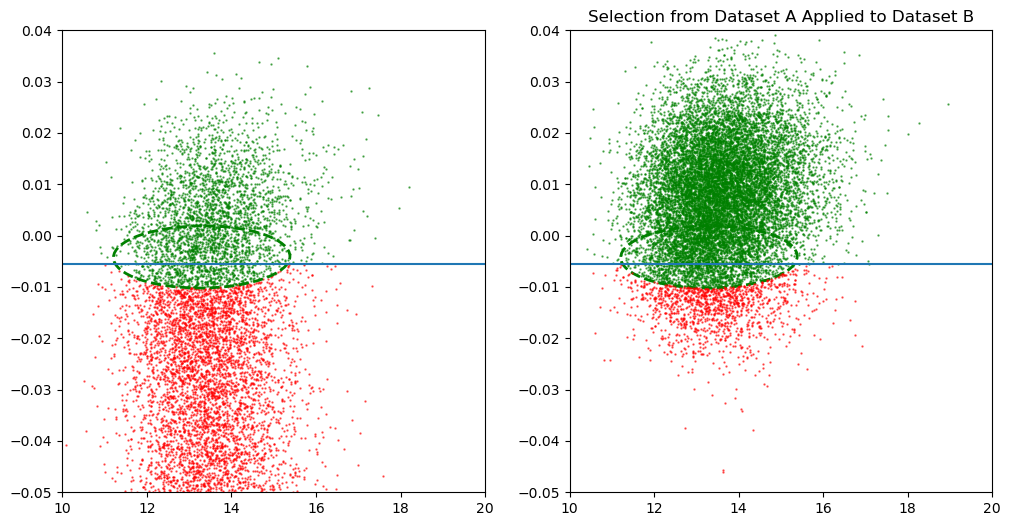

In [245]:
from matplotlib.colors import LogNorm
xA =  chi2_single#(argmax_single_OF/argmax_single -1)*100
yA = filtered_amp_single/fitted_amp_single-1
xB =  chi2_pileup#(argmax_pileup_OF/argmax_pileup-1)*100
yB =  filtered_amp_pileup/fitted_amp_pileup-1
cut = np.percentile(yA,10)
rp = np.sum(yB<cut)/len(yB)
print(channel,np.sum(yA>cut)/len(yA),rp,fn.calculate_BI(rp,0.8)*1e5)
cut = np.percentile(yA,15)
sel= (yA<0.00)&(yA>-0.01)&(xA<20)&(xA>10)
dataA = np.column_stack((xA[sel], yA[sel]))
# Compute ellipse parameters from dataset A
mean_A = np.median(dataA, axis=0)
cov_A = np.cov(dataA, rowvar=False)
confidence = 0.9
mask_A = ha.get_mask(xA, yA, mean_A, cov_A, confidence=confidence)
# Get inliers/outliers in B based on ellipse from A
mask_B = ha.get_mask(xB, yB, mean_A, cov_A, confidence=confidence)
# print(channel, np.sum(mask_A)/len(xA),1-np.sum(mask_B)/len(xB),fn.calculate_BI(1-np.sum(mask_B)/len(xB),0.8)*1e5)
mask_A_b = mask_A|(yA>cut)
mask_B_b = mask_B|(yB>cut)
print(channel, np.sum(mask_A)/len(xA),1-np.sum(mask_B)/len(xB),fn.calculate_BI(1-np.sum(mask_B)/len(xB),0.8)*1e5)
print(channel, np.sum(mask_A_b)/len(xA),1-np.sum(mask_B_b)/len(xB),fn.calculate_BI(1-np.sum(mask_B_b)/len(xB),0.8)*1e5)
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(12,6))
# # ax.scatter(xA, yA, s=0.5, c='blue', label='All A', alpha=0.6)
ax1.scatter(xB[mask_B_b], yB[mask_B_b], s=0.5, c='green', label='Inliers in B', alpha=0.6)
ax1.scatter(xB[~mask_B_b], yB[~mask_B_b], s=0.5, c='red', label='Outliers in B', alpha=0.6)
# ax.hist2d(xB, yB,np.arange(-0.1,0.04,0.0005) , label='All A', norm=LogNorm())
ha.draw_confidence_ellipse(mean_A, cov_A, confidence=confidence, ax=ax2, linestyle='--',edgecolor="g")
ax1.hlines(cut,0,70)
# ax.legend()
plt.title("Selection from Dataset A Applied to Dataset B")

ax1.set_ylim(-0.05,0.04)
ax1.set_xlim(10,20)

ax2.scatter(xA[mask_A_b], yA[mask_A_b], s=0.5, c='green', label='All A', alpha=0.6)
ax2.scatter(xA[~mask_A_b], yA[~mask_A_b], s=0.5, c='red', label='All A', alpha=0.6)
# ax.hist2d(xA, yA,np.arange(-0.1,0.04,0.0005) , label='All A', norm=LogNorm())
# ax.scatter(xB[mask_B_b], yB[mask_B_b], s=0.5, c='green', label='Inliers in B', alpha=0.6)
# ax.scatter(xB[~mask_B_b], yB[~mask_B_b], s=0.5, c='red', label='Outliers in B', alpha=0.6)
ha.draw_confidence_ellipse(mean_A, cov_A, confidence=confidence, ax=ax1, linestyle='--',edgecolor="g")
ax2.hlines(cut,0,70)
# ax.legend()
plt.title("Selection from Dataset A Applied to Dataset B")
plt.ylim(-0.05,0.04)
plt.xlim(10,20)
plt.show()



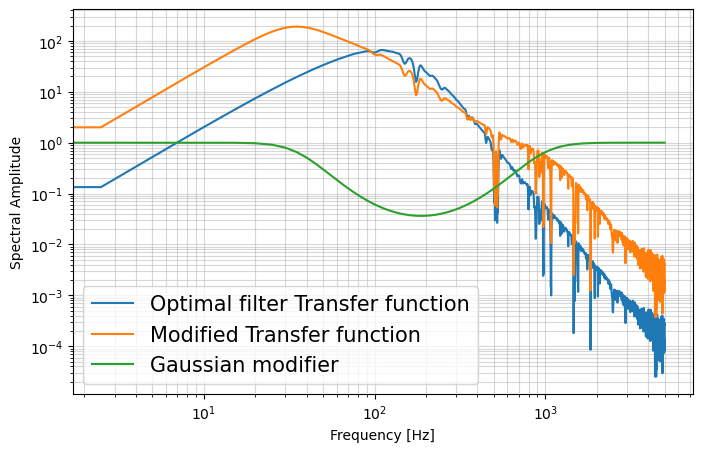

In [18]:
channel = 9
meanpulse, bslspec = ds.get_meanpulse_ANPS(channel)

best_params,_= ds.get_best_param(channel)
mg = fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
transf_OF,_ = an.compute_transfer_simple(meanpulse,bslspec)
transf_PU,_ = an.compute_transfer_simple(meanpulse,bslspec*mg)
plt.figure(figsize = (8,5))
plt.plot(np.fft.fftfreq(4000,1e-4)[:2000],np.abs(transf_OF[:2000]),label="Optimal filter Transfer function")
plt.plot(np.fft.fftfreq(4000,1e-4)[:2000],np.abs(transf_PU[:2000]),label="Modified Transfer function")
plt.plot(np.fft.fftfreq(2000,1e-4)[:1000],np.abs(1/mg[:1000]),label="Gaussian modifier")
# ft = fn.modified_gaussian(np.fft.fftfreq(4000,1e-4),100,np.log(1000),0.2,1)[:2000]
# print(np.fft.fftfreq(4000,1e-4)[:2000][ft>ft.max()*0.1])
# plt.plot(np.fft.fftfreq(4000,1e-4)[:2000],np.abs(transf_OF[:2000]*ft))
# plt.plot(np.fft.fftfreq(4000,1e-4)[:2000],ft)
# plt.plot(np.fft.fftfreq(2000,1e-4)[:1000],np.abs(np.fft.fft(meanpulse)[:1000]))
# plt.plot(np.fft.fftfreq(2000,1e-4)[:1000],1/bslspec[:1000])
plt.xlabel("Frequency [Hz]")
plt.ylabel("Spectral Amplitude")
plt.xscale("log")
plt.yscale("log")
plt.grid(True,"both",alpha=0.5)
plt.legend(fontsize=15)
plt.show()

In [13]:
channels = [3,5,9,11,13,15,17,19]
for i,channel in enumerate(channels):
    database_url = "sqlite:///" + ds.main_dir + f"/channel{channel}/study_channel{channel}.db"
    study = optuna.load_study(study_name=f"study_channel{channel}_multgauss", 
                              storage=database_url)
    trials = study.get_trials(deepcopy=False)
    filtered_trials = [
        t for t in trials 
        if t.values is not None and
           300.0 <= t.params.get("f0", 300.0) <= 3000.0 and
           t.params.get("sigma") == study.best_params["sigma"]
    ]    
    try:
        optuna.delete_study(study_name="study_channel{channel}_multgauss_singlesigma", storage=database_url)
    except KeyError:
        pass  # study doesn't exist yet — that's fine

    filtered_study = optuna.create_study(direction=study.direction,study_name=f"study_channel{channel}_multgauss_singlesigma", 
                              storage=database_url,load_if_exists=True)

    # Add the filtered trials
    filtered_study.add_trials(filtered_trials)

[I 2025-04-23 10:17:42,337] Using an existing study with name 'study_channel3_multgauss_singlesigma' instead of creating a new one.
[I 2025-04-23 10:18:20,425] A new study created in RDB with name: study_channel5_multgauss_singlesigma
[I 2025-04-23 10:18:57,502] A new study created in RDB with name: study_channel9_multgauss_singlesigma
[I 2025-04-23 10:19:37,712] A new study created in RDB with name: study_channel11_multgauss_singlesigma
[I 2025-04-23 10:20:18,119] A new study created in RDB with name: study_channel13_multgauss_singlesigma
[I 2025-04-23 10:20:55,584] A new study created in RDB with name: study_channel15_multgauss_singlesigma
[I 2025-04-23 10:21:28,299] A new study created in RDB with name: study_channel17_multgauss_singlesigma
[I 2025-04-23 10:22:01,464] A new study created in RDB with name: study_channel19_multgauss_singlesigma


In [225]:
channels = [3,5,9,11,13,15,17,19]
from plotly.subplots import make_subplots
fig = make_subplots(
    rows=2, cols=4, 
    subplot_titles=[f"channel {channel}" for channel in channels] # This makes all plots use the same colorbar
)
for i,channel in enumerate(channels):
    row, col = divmod(i, 4)
    partial = 1 if channel in [17] else 0
    fig.update_xaxes(title_text="A", row=row + 1, col=col + 1)
    if col == 0:
        fig.update_yaxes(title_text="f0", row=row + 1, col=col + 1)
    print(f"###################################### channel{channel} ######################################")
    database_url = "sqlite:///" + ds.main_dir + f"/study_channel{channel}.db"
    storage = optuna.storages.RDBStorage(url=database_url)
    # studies = optuna.get_all_study_summaries(storage=database_url)
    # 
    # for study in studies:
    #     print(f"Study name: {study.study_name}")
    #     # You can also print other fields
    #     print(f"Direction: {study.direction}")
    #     print(f"Start time: {study.datetime_start}")
    study = optuna.load_study(study_name=f"study_channel{channel}_divgauss", 
                              storage=database_url)
    # new_study = add_second_objective(study, lambda v: calculate_BI(v,0.8))
    
    contour_fig = optuna.visualization.plot_contour(study, params=["A", "f0"],target=lambda t:  t.value*1e5)
    
    for trace in contour_fig.data:
        if "z" in trace:  # Only apply coloraxis to heatmaps
            trace.update(coloraxis="coloraxis") # Ensures all share the same colorbar
        if trace.type == "scatter":  # ✅ Correct check for scatter plots
            continue
            # trace.update(marker=dict(size=1))
        fig.add_trace(trace, row=row + 1, col=col + 1)
    fig.add_trace(
    go.Scatter(x=[study.best_params["A"]], y=[study.best_params["f0"]], mode='markers', marker=dict(size=10, color='purple'),showlegend=False),
    row=row + 1, col=col + 1
)
    print(study.best_params, study.best_value)
fig.update_layout(
    height=800, width=1200, 
    title_text="",
    coloraxis=dict(colorscale="RdBu"),  # Shared color scale
    coloraxis_colorbar=dict(title="BI (1e-5 bkky)")  # Single colorbar
)
show(fig)

###################################### channel3 ######################################
{'A': 34.04303619623306, 'f0': 187.420393666626, 'sigma': 0.6} 5.375667046998032e-05
###################################### channel5 ######################################
{'A': 34.04303619623306, 'f0': 187.420393666626, 'sigma': 0.6} 5.941896942036751e-05
###################################### channel9 ######################################
{'A': 26.460478569799445, 'f0': 187.420393666626, 'sigma': 0.6} 6.274249271733394e-05
###################################### channel11 ######################################
{'A': 43.798463826000955, 'f0': 187.420393666626, 'sigma': 0.6} 5.815286530723749e-05
###################################### channel13 ######################################
{'A': 43.798463826000955, 'f0': 187.420393666626, 'sigma': 0.6} 5.178717518288915e-05
###################################### channel15 ######################################
{'A': 34.04303619623306, 'f0': 187.420393666626

In [ ]:
channels = [3,5,9,11,13,15,17,19]
from optuna.storages import RDBStorage

for i,channel in enumerate(channels):
    database_url = "sqlite:///" + ds.main_dir + f"/channel{channel}/study_channel{channel}.db"
    study = optuna.load_study(study_name=f"study_channel{channel}_multgauss", 
                              storage=database_url)
    trials = study.get_trials(deepcopy=False)
    try:
        optuna.delete_study(study_name="study_channel{channel}_multgauss_extended", storage=database_url)
    except KeyError:
        pass  # study doesn't exist yet — that's fine
    for t in trials:
        if "f0" in t.params:
            t.params["f0"] = float(int(t.params["f0"])+1)
    search_space = {"A": np.exp(np.linspace(np.log(1.999), np.log(120), 20)).tolist(), "f0": np.exp(np.linspace(np.log(300), np.log(3000), 20)).tolist()+np.exp(np.linspace(np.log(3000), np.log(5000), 10)).tolist(),
                    "sigma": np.arange(0.1, 0.8, 0.1).tolist()+np.arange(0.8, 2.1, 0.1).tolist()}
    storage = RDBStorage(url=database_url)
    new_study = optuna.create_study(storage=storage, study_name=f"study_channel{channel}_multgauss_extended", direction='maximize',
                                load_if_exists=True, sampler=optuna.samplers.GridSampler(search_space))

    # Add the filtered trials
    new_study.add_trials(trials)


[I 2025-04-23 10:34:33,896] Using an existing study with name 'study_channel3_multgauss_extended' instead of creating a new one.
[I 2025-04-23 10:37:46,735] A new study created in RDB with name: study_channel5_multgauss_extended
[I 2025-04-23 10:41:04,510] A new study created in RDB with name: study_channel9_multgauss_extended
[I 2025-04-23 10:45:14,409] A new study created in RDB with name: study_channel11_multgauss_extended
[I 2025-04-23 10:48:27,980] A new study created in RDB with name: study_channel13_multgauss_extended
[I 2025-04-23 10:56:48,540] A new study created in RDB with name: study_channel15_multgauss_extended
[I 2025-04-23 11:04:32,897] A new study created in RDB with name: study_channel17_multgauss_extended
